# Draining a meltwater lake: how the ice shelf flexes back up

This notebook takes a real ice-shelf surface and fills it with meltwater using **fill-spill-merge**. It then picks one of the lakes this makes and drains it. The viscoelastic plate model in this folder computes how the floating ice flexes back up, and the response is recorded as an `xarray.Dataset` and saved to NetCDF.

| step | tool |
|---|---|
| route meltwater, find lakes | `fill_spill_merge`: the original algorithm (Barnes, Callaghan & Wickert 2021), called through the Python wrapper [`jkingslake/fillspillmerge`](https://github.com/jkingslake/fillspillmerge) |
| flex the shelf | `FDPlate` from [`viscoelastic_plate.py`](viscoelastic_plate.py): a Maxwell viscoelastic plate floating on sea water, with grounded ice held fixed |
| glue | [`lake_routing.py`](lake_routing.py): data loading, lake labelling, moving fields between the routing and plate grids, and the drainage experiment |

Companion notebooks:

* [`coupled_routing_flexure.ipynb`](coupled_routing_flexure.ipynb) runs the routing and the flexure together in time.
* [`drainage_reorganisation.ipynb`](drainage_reorganisation.ipynb) asks where the next summer's meltwater goes after a lake has drained.

## The idea: simulate only the unloading

Let $q_L(x,y) = \rho_w g\,d(x,y)$ be the load of a lake of depth $d$. Suppose the lake has sat on the shelf long enough for the ice to relax completely. A relaxed Maxwell plate carries no bending moment, so it floats in **local isostasy**, $w = q_L/k$ with $k = \rho_{sw} g$.

The model is linear. So the state after the lake drains is that relaxed state **plus** the response of an *unstressed* plate to the load $-q_L$. We compute only that second part, starting from rest. Every output is therefore a *change caused by the drainage*:

* $\Delta w(x,y,t)$, the change in deflection (positive down), so the uplift is $-\Delta w$;
* the surface stresses, which come entirely from the drainage, because the relaxed state has none.

Two limits frame the answer:

* **While the water drains (hours)** the ice responds elastically. This spreads the rebound over a flexural length $\ell = (D/k)^{1/4}$ and resists rebound on scales shorter than about $2\pi\ell$.
* **Over days to months** it creeps towards isostasy, $\Delta w \to -q_L/k$. The old lake floor rises by $\rho_w/\rho_{sw} \approx 97\%$ of the water depth.

We take the DEM to be that relaxed, loaded surface: the lake basin as it was just before the lake drained. Section 7 checks how long a lake must sit for "fully relaxed" to be a good assumption.

## 1. Set-up

In [1]:
import os, time
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from scipy import ndimage as ndi

import plotstyle as ps
from plotstyle import show_map, hillshade
from viscoelastic_beam import IceShelf
import lake_routing as lr
from lake_routing import DAY, load_dem, floating_mask, route, find_lakes, pick_lake, ShelfPlate, drain_lake

ps.apply()
pd.set_option("display.precision", 2)

# The fill-spill-merge wrapper must be importable: pip-install it, or set
# FILLSPILLMERGE_PATH to the folder where you cloned and built it, e.g.
# os.environ["FILLSPILLMERGE_PATH"] = os.path.expanduser("~/fsm_pywrapper/fillspillmerge")
lr._import_fsm()
OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

## 2. The surface and the grounding line

`dem_small_2.tif` is a 33 km × 98 km subset of REMA in Dronning Maud Land (about 70.7° S, 22.7° E), at 32 m. We average it to 64 m, which keeps each fill-spill-merge call to about half a second.

Fill-spill-merge only lets water leave the domain through ocean cells (at or below the ocean level) that touch the edge. Like the repository's Nivlisen DEM, `load_dem` therefore sets the outermost ring of cells to the ocean level, so water reaching the edge of the domain leaves it. The few nodata cells are filled from their neighbours.

The 500 m mask in `data/` says which ice is floating; the red line is the grounding line.

In [2]:
DEM_FILE = "../python/notebooks/rema_subsets/dem_small_2.tif"
dem = load_dem(DEM_FILE, coarsen=2)          # 32 m -> 64 m; the edge ring becomes an ocean outlet
floating = floating_mask(dem)                # from data/Mask_Antarctica_v02.tif
dx = abs(float(dem.x[1] - dem.x[0]))
print(f"{dem.sizes['y']} x {dem.sizes['x']} cells of {dx:.0f} m "
      f"({dem.sizes['x'] * dx / 1e3:.0f} km x {dem.sizes['y'] * dx / 1e3:.0f} km); "
      f"{100 * float(floating.mean()):.0f}% floating")

1536 x 512 cells of 64 m (33 km x 98 km); 39% floating


## 3. Fill the surface with fill-spill-merge

Every cell releases the same 0.5 m of water. Fill-spill-merge moves it downhill and fills depressions. When a depression is full, the water spills on to the next; when two lakes meet, they merge. The result is the equilibrium water depth. `find_lakes` labels each connected wet area and tabulates it.

In [6]:
MELT = 0.5                                   # m of water released in every cell
t0 = time.perf_counter()
water = route(dem, MELT)
print(f"fill-spill-merge on {dem.size:,} cells: {time.perf_counter() - t0:.2f} s")
area = lr.cell_area(dem)
print(f"melt released {MELT * dem.size * area / 1e6:,.0f} Mm³; held in lakes {float(water.sum()) * area / 1e6:,.0f} Mm³ "
      "(the rest left the domain)")

labels, lakes = find_lakes(water, floating)
table = lakes.to_dataframe().assign(
    volume_Mm3=lambda d: d.volume / 1e6, area_km2=lambda d: d.area / 1e6,
    x_km=lambda d: d.x_centre / 1e3, y_km=lambda d: d.y_centre / 1e3,
)[["volume_Mm3", "area_km2", "max_depth", "floating_fraction", "x_km", "y_km"]]
print(f"{len(table)} lakes; the 10 largest:")
table.head(10)

fill-spill-merge on 786,432 cells: 1.67 s
melt released 1,611 Mm³; held in lakes 586 Mm³ (the rest left the domain)
8314 lakes; the 10 largest:


,volume_Mm3,area_km2,max_depth,floating_fraction,x_km,y_km
lake,,,,,,
6319,344.05,49.03,31.26,0.94,809.55,1947.25
4460,54.56,10.36,18.39,0.61,806.07,1956.34
7999,23.73,4.69,13.12,0.00,818.47,1930.03
8030,18.12,2.47,17.88,0.00,825.87,1925.60
8212,16.95,4.55,9.39,0.00,803.45,1910.72
6460,10.13,2.83,11.06,0.08,804.21,1948.91
8008,10.07,2.50,9.97,0.00,823.15,1928.44
526,7.43,4.87,7.37,1.00,816.69,1989.10
2,7.09,7.32,3.27,1.00,815.29,1996.72


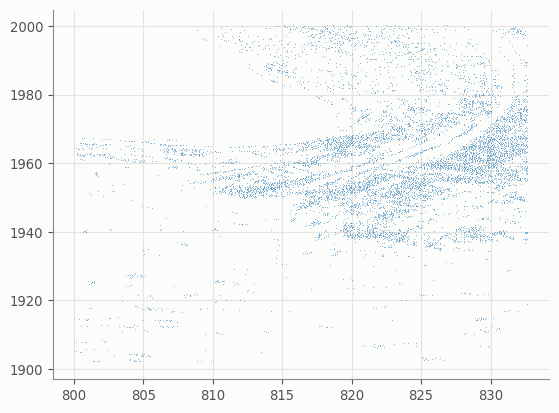

In [9]:
plt.plot(lakes.x_centre / 1e3, lakes.y_centre / 1e3, ",", ms=5, alpha=0.5)

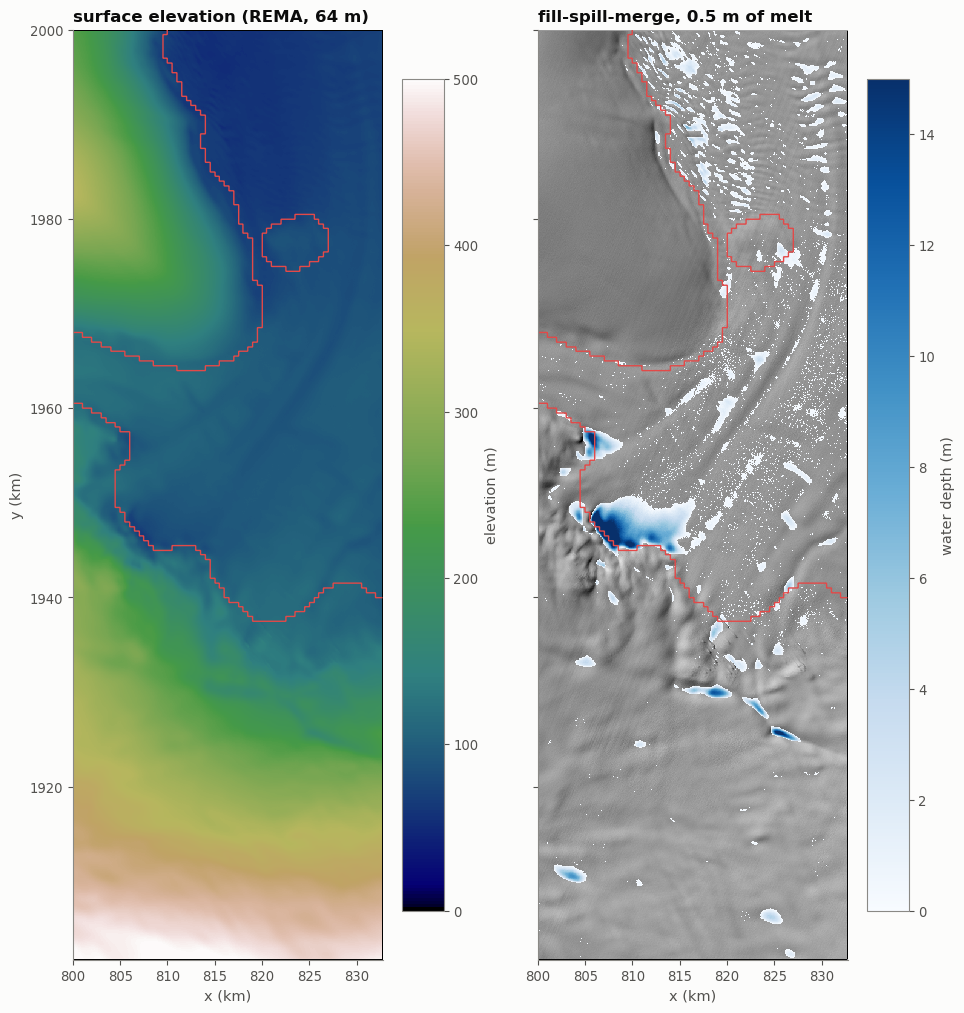

In [10]:
def grounding_line(ax, mask):
    ax.contour(mask.x / 1e3, mask.y / 1e3, mask.astype(float), levels=[0.5],
               colors=ps.TENSION, linewidths=1.0)

hs = hillshade(dem)
fig, ax = plt.subplots(1, 2, figsize=(11, 13.5), sharey=True)
show_map(ax[0], dem, "surface elevation (REMA, 64 m)", cbar="elevation (m)", cmap="gist_earth", vmin=0, vmax=500)
show_map(ax[1], hs, "fill-spill-merge, 0.5 m of melt", cmap="gray", vmin=0, vmax=1)
im = show_map(ax[1], water.where(water > 0.05), cmap="Blues", vmin=0, vmax=15)
plt.colorbar(im, ax=ax[1], shrink=0.8, label="water depth (m)")
for a in ax:
    grounding_line(a, floating)
ax[1].set_ylabel("");

## 4. Choose a lake

`pick_lake` chooses a lake in one of three ways:

* by label: `pick_lake(lakes, lake=...)`;
* by location: `pick_lake(lakes, near=(x, y))`, which takes the lake whose centre is nearest the point;
* by default: the largest lake that is at least 90% afloat.

The default here is the big lake ponded against the grounding line, which is typical of where large lakes form. Section 9 repeats the experiment for a smaller lake out on the shelf.

In [12]:
BOX

{'x': slice(np.float64(799524.0), np.float64(822660.0), None),
 'y': slice(np.float64(1956828.0), np.float64(1938364.0), None)}

lake 6319: 344 Mm³ over 49.0 km², max depth 31.3 m, 94% afloat


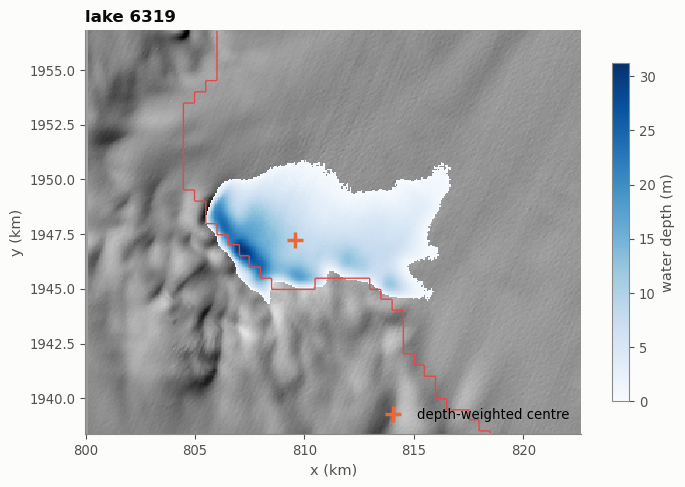

In [11]:
LAKE = pick_lake(lakes)
info = lakes.sel(lake=LAKE)
lake_depth = water.where(labels == LAKE, 0.0).rename("lake_depth")

print(f"lake {LAKE}: {float(info.volume) / 1e6:.0f} Mm³ over {float(info.area) / 1e6:.1f} km², "
      f"max depth {float(info.max_depth):.1f} m, {100 * float(info.floating_fraction):.0f}% afloat")

def box_around(depth, margin=6e3):
    wet = depth > 0
    xs, ys = depth.x.values[wet.any("y").values], depth.y.values[wet.any("x").values]
    return dict(x=slice(xs.min() - margin, xs.max() + margin), y=slice(ys.max() + margin, ys.min() - margin))

BOX = box_around(lake_depth)
fig, ax = plt.subplots(figsize=(8, 5.5))
show_map(ax, hs.sel(**BOX), f"lake {LAKE}", cmap="gray", vmin=0, vmax=1)
im = show_map(ax, lake_depth.sel(**BOX).where(lake_depth.sel(**BOX) > 0), cmap="Blues", vmin=0)
plt.colorbar(im, ax=ax, shrink=0.8, label="water depth (m)")
grounding_line(ax, floating.sel(**BOX))
ax.plot(float(info.x_centre) / 1e3, float(info.y_centre) / 1e3, "+", color=ps.ELASTIC, ms=12, mew=2.5,
        label="depth-weighted centre")
ax.legend(loc="lower right");

## 5. The plate

The plate needs a uniform thickness, and the shelf thickness is not in this repository. We take $H = 400$ m: change it here to test other values. $\ell$ scales as $H^{3/4}$; the relaxation times do not depend on $H$.

The plate grid is twice as coarse as the routing grid (128 m, about $\ell/7$, which is plenty). Plate nodes that are mostly grounded are held at $w = 0$, so the grounding line acts as a clamped edge, as do the edges of the domain. Loads move down to the plate grid as block averages, which conserves water volume. Deflections move back up by bilinear interpolation.

In [13]:
shelf = IceShelf(H=400.0)                     # E = 1 GPa, eta = 1e14 Pa s, nu = 0.3, nu_v = 0.5
plate = ShelfPlate(dem, floating, shelf, coarsen=2)
tau1, tau2 = np.array(shelf.taus) / DAY
print(f"H = {shelf.H:.0f} m:  D = {shelf.D:.2e} N m,  flexural length ell = {shelf.ell:.0f} m")
print(f"relaxation times: tau1 = {tau1:.1f} d (isotropic part), tau2 = {tau2:.1f} d (deviatoric part)")
print(f"plate grid {plate.shape[0]} x {plate.shape[1]} at {plate.dx:.0f} m (ell/{shelf.ell / plate.dx:.0f}), "
      f"{int((~plate.plate.fixed).sum()):,} free nodes")

H = 400 m:  D = 5.86e+15 N m,  flexural length ell = 873 m
relaxation times: tau1 = 4.9 d (isotropic part), tau2 = 3.0 d (deviatoric part)
plate grid 768 x 256 at 128 m (ell/7), 74,782 free nodes


## 6. Drain the lake

The water leaves over 12 hours; drainage by hydrofracture takes hours to days. The plate takes short steps while the water drains, steps of 6 hours to day 20, then daily steps. `drain_lake` keeps maps at the output times, plus time series at every step:

* the mean uplift over the lake, also as a fraction of its isostatic value;
* the uplift at two probe points: the lake's depth-weighted centre, and its deepest point that lies at least $\ell$ from grounded ice.

In [7]:
DRAIN = 0.5 * DAY
OUT = np.array([0.5, 2, 10, 30, 100, 365]) * DAY

# probes: the lake's depth-weighted centre, and its deepest point at least one
# flexural length from grounded ice (closer than that the grounding line pins the ice)
dist_gl = xr.DataArray(ndi.distance_transform_edt(floating.values) * dx, coords=dem.coords, dims=dem.dims)
deep = lake_depth.where(dist_gl > shelf.ell, 0.0)
iy, ix = np.unravel_index(int(deep.argmax()), deep.shape)
x_deep, y_deep = float(dem.x[ix]), float(dem.y[iy])
probes = {"deep": (x_deep, y_deep), "centre": (float(info.x_centre), float(info.y_centre))}
print(f"'deep' probe: {float(deep.max()):.1f} m of water, {float(dist_gl[iy, ix]):.0f} m from grounded ice")
t0 = time.perf_counter()
resp = drain_lake(plate, lake_depth, OUT, drain_time=DRAIN, probes=probes)
print(f"{resp.sizes['step_time'] - 1} plate steps covering a year: {time.perf_counter() - t0:.0f} s")
resp

'deep' probe: 17.1 m of water, 923 m from grounded ice


433 plate steps covering a year: 34 s


<xarray.Dataset> Size: 88MB
Dimensions:           (time: 6, y: 768, x: 256, part: 2, step_time: 434,
                       probe: 2)
Coordinates:
  * time              (time) float64 48B 4.32e+04 1.728e+05 ... 3.154e+07
    time_days         (time) float64 48B 0.5 2.0 10.0 30.0 100.0 365.0
  * y                 (y) float64 6kB 2e+06 2e+06 2e+06 ... 1.902e+06 1.902e+06
  * x                 (x) float64 2kB 8.001e+05 8.002e+05 ... 8.327e+05
  * part              (part) <U10 80B 'isotropic' 'deviatoric'
  * step_time         (step_time) float64 3kB 0.0 4.32e+03 ... 3.154e+07
    step_time_days    (step_time) float64 3kB 0.0 0.05 0.1 ... 363.0 364.0 365.0
  * probe             (probe) <U6 48B 'deep' 'centre'
Data variables: (12/14)
    w                 (time, y, x) float64 9MB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    q                 (time, y, x) float64 9MB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    mu                (time, part, y, x) float64 19MB 0.0 0.0 0.0 ... 0.0 0.0
    sxx               (time, y, x) float64 9MB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    syy               (time, y, x) float64 9MB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    sxy               (time, y, x) float64 9MB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    ...                ...
    uplift_max        (step_time) float64 3kB -0.0 0.7775 1.558 ... 20.09 20.1
    uplift_lake_mean  (step_time) float64 3kB 0.0 0.3364 0.6743 ... 8.949 8.951
    rebound_fraction  (step_time) float64 3kB 0.0 0.02947 ... 0.7839 0.7841
    uplift_probe      (step_time, probe) float64 7kB -0.0 -0.0 ... 18.86 7.969
    lake_load         (y, x) float64 2MB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    uplift_isostatic  (y, x) float64 2MB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
Attributes: (12/20)
    E:               1000000000.0
    nu:              0.3
    nu_v:            0.5
    eta:             100000000000000.0
    rho_i:           917.0
    rho_sw:          1028.0
    ...              ...
    tau_2:           260000.00000000003
    model:           FDPlate
    experiment:      lake drainage from a fully relaxed state (unloading only)
    drain_time_s:    43200.0
    lake_volume_m3:  344058677.93766224
    plate_dx:        128.0

### Uplift maps

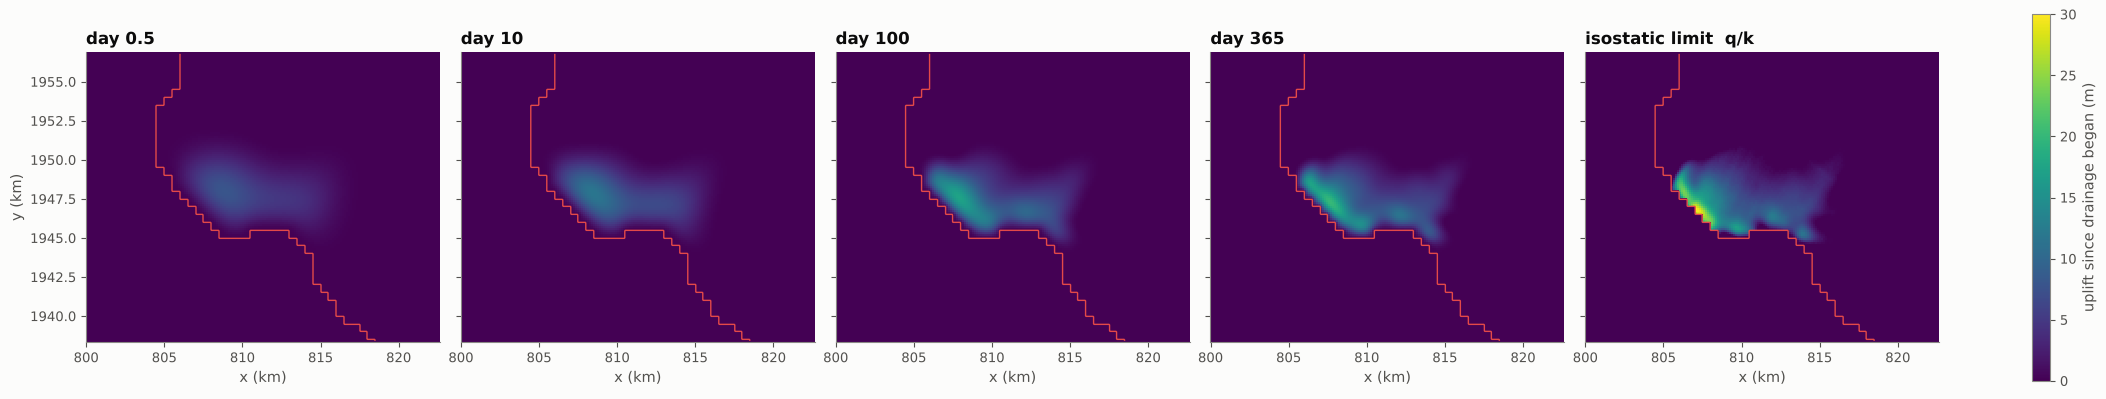

In [8]:
vmax = float(resp.uplift_isostatic.sel(**BOX).max())
fig, ax = plt.subplots(1, 5, figsize=(21, 4.4), sharey=True, constrained_layout=True)
for a, td in zip(ax, [0.5, 10, 100, 365]):
    im = show_map(a, resp.uplift.sel(time_days=td, method="nearest").sel(**BOX), f"day {td:g}",
                  cmap="viridis", vmin=0, vmax=vmax)
show_map(ax[4], resp.uplift_isostatic.sel(**BOX), "isostatic limit  q/k", cmap="viridis", vmin=0, vmax=vmax)
for a in ax:
    grounding_line(a, floating.sel(**BOX))
for a in ax[1:]:
    a.set_ylabel("")
fig.colorbar(im, ax=ax, shrink=0.85, label="uplift since drainage began (m)");

### How fast does it rise?

The left panel shows the load-weighted mean uplift over the lake, as a fraction of its isostatic value. The right panel shows the uplift at the two probe points, with their isostatic values dashed. Time is logarithmic, and the grey band marks the 12 hours of drainage.

A point need not rise monotonically towards its isostatic value. The plate spreads the rebound of the deep water next to it, so a point can overshoot for a while before the ice relaxes to local isostasy.

day   0.5:   30% of the isostatic rebound
day    10:   45% of the isostatic rebound
day   100:   68% of the isostatic rebound
day   365:   78% of the isostatic rebound


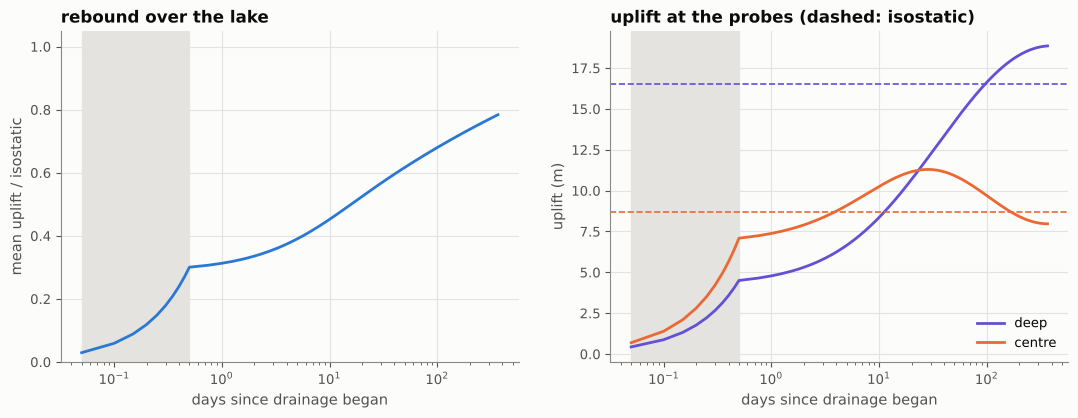

In [9]:
td = resp.step_time_days.values
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
ax[0].semilogx(td[1:], resp.rebound_fraction[1:], color=ps.VISCO)
ax[0].set(xlabel="days since drainage began", ylabel="mean uplift / isostatic", ylim=(0, 1.05),
          title="rebound over the lake")
for name, c in zip(resp.probe.values, [ps.ACCENT, ps.ELASTIC]):
    ax[1].semilogx(td[1:], resp.uplift_probe.sel(probe=name)[1:], color=c, label=name)
    iso = float(resp.uplift_isostatic.sel(x=probes[name][0], y=probes[name][1], method="nearest"))
    ax[1].axhline(iso, color=c, ls="--", lw=1.2)
ax[1].set(xlabel="days since drainage began", ylabel="uplift (m)", title="uplift at the probes (dashed: isostatic)")
ax[1].legend()
for a in ax:
    a.axvspan(td[1], DRAIN / DAY, color=ps.GRID, zorder=0)
for d_ in (0.5, 10, 100, 365):
    f = float(resp.rebound_fraction.sel(step_time_days=d_, method="nearest"))
    print(f"day {d_:>5g}: {100 * f:4.0f}% of the isostatic rebound")

### A profile through the lake

This is a west–east line through the 'deep' probe. It shows the DEM surface before drainage, the lake on it, and the surface after drainage at several times; the dashed line is the isostatic limit. Uplift on the 64 m routing grid comes from `plate.to_grid`.

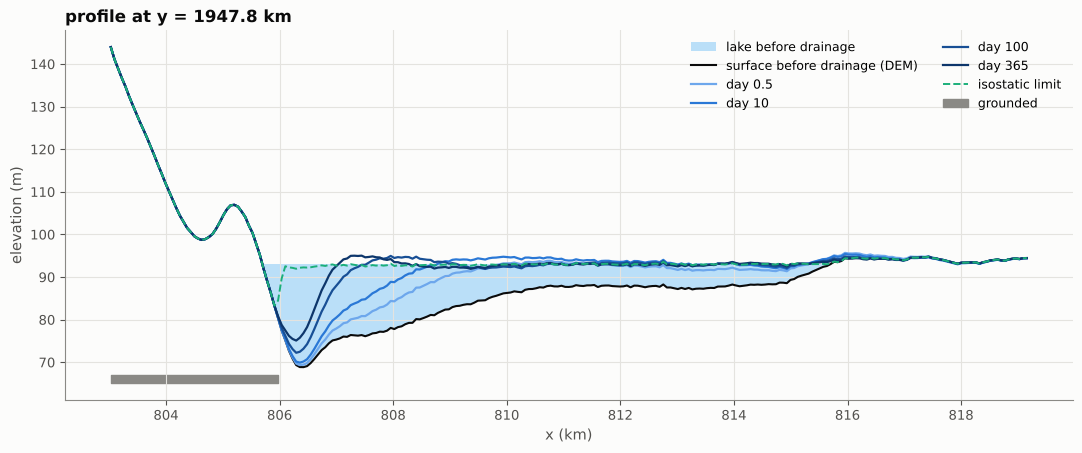

In [10]:
line = dict(y=y_deep, method="nearest")
PX = box_around(lake_depth, margin=2.5e3)["x"]
xs = dem.x.sel(x=PX)
s0 = dem.sel(**line).sel(x=PX)
d0 = lake_depth.sel(**line).sel(x=PX)
fl0 = floating.sel(**line).sel(x=PX)
fig, ax = plt.subplots(figsize=(13, 4.8))
ax.fill_between(xs / 1e3, s0, s0 + d0, where=d0 > 0, color=ps.WATER, alpha=0.35, lw=0, label="lake before drainage")
ax.plot(xs / 1e3, s0, color=ps.INK, lw=1.5, label="surface before drainage (DEM)")
for t_, c in zip([0.5, 10, 100, 365], [ps.SEQ[1], ps.SEQ[4], ps.SEQ[7], ps.SEQ[9]]):
    up = plate.to_grid(resp.uplift.sel(time_days=t_, method="nearest")).sel(**line).sel(x=PX)
    ax.plot(xs / 1e3, s0 + up, color=c, lw=1.6, label=f"day {t_:g}")
iso_line = plate.to_grid(resp.uplift_isostatic).sel(**line).sel(x=PX)
ax.plot(xs / 1e3, s0 + iso_line, color=ps.ISO, ls="--", lw=1.4, label="isostatic limit")
g = ~fl0.values
ax.fill_between(xs / 1e3, ax.get_ylim()[0], ax.get_ylim()[0] + 2, where=g, color=ps.MUTED, step="mid",
                label="grounded")
ax.set(xlabel="x (km)", ylabel="elevation (m)", title=f"profile at y = {y_deep / 1e3:.1f} km")
ax.legend(ncol=2, fontsize=9);

### Surface stress

The largest principal stress at the upper surface is shown, with tension positive. Draining a relaxed lake bends the ice *upwards* where the water was, so the surface there goes into **tension**. The tension is greatest just after the water leaves, then decays as the ice creeps.

Stresses within two plate cells of grounded nodes are hidden: there the stair-stepped 500 m mask makes them unreliable.

day   0.5: largest tension  1203 kPa
day    10: largest tension   700 kPa
day   100: largest tension   294 kPa


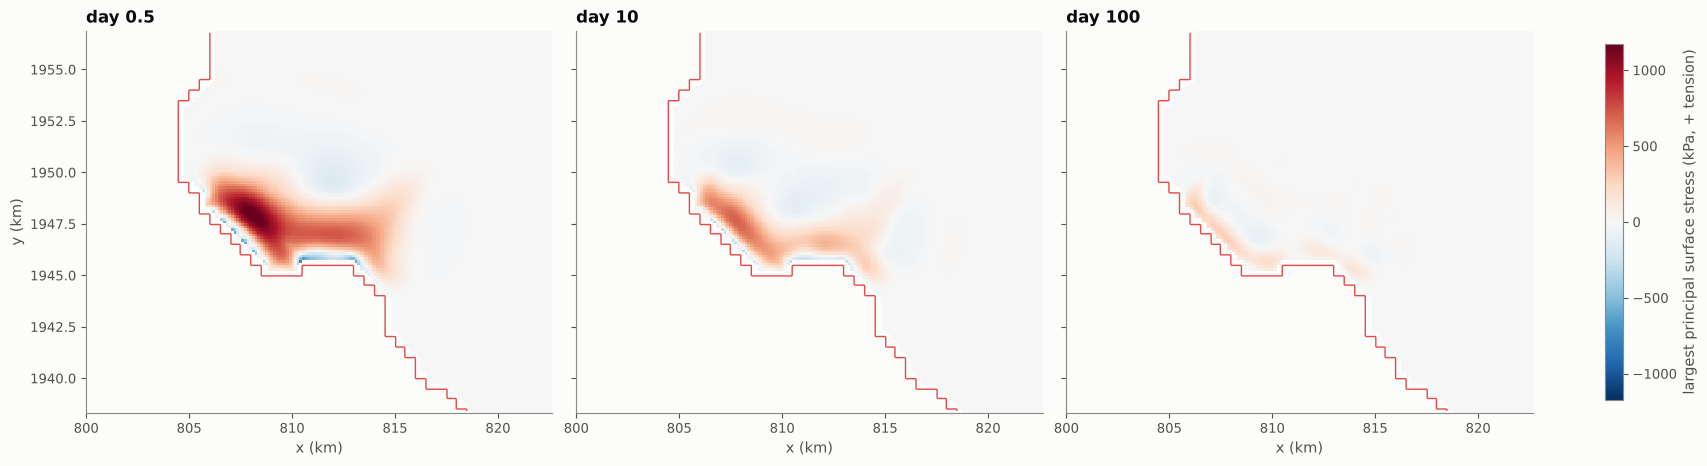

In [11]:
near_gl = xr.DataArray(ndi.binary_dilation(plate.plate.fixed, iterations=2), dims=("y", "x"))
s1 = (resp.sigma1.where(~near_gl) / 1e3).sel(**BOX)
lim = float(np.nanpercentile(np.abs(s1.sel(time_days=0.5, method="nearest")), 99.9))
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6), sharey=True, constrained_layout=True)
for a, t_ in zip(ax, [0.5, 10, 100]):
    im = show_map(a, s1.sel(time_days=t_, method="nearest"), f"day {t_:g}", cmap="RdBu_r", vmin=-lim, vmax=lim)
    grounding_line(a, floating.sel(**BOX))
    print(f"day {t_:>5g}: largest tension {float(s1.sel(time_days=t_, method='nearest').max()):5.0f} kPa")
for a in ax[1:]:
    a.set_ylabel("")
fig.colorbar(im, ax=ax, shrink=0.85, label="largest principal surface stress (kPa, + tension)");

## 7. How long must a lake sit before it is "fully relaxed"?

Linearity also tells us what happens if the lake drains before the ice has fully relaxed. Let $U(t)$ be the uplift computed above (the response of a plate at rest to removing the load). Loading a plate at rest gives the same response with the opposite sign. Now suppose the lake filled (just as quickly), sat for $T_h$ days, and then drained. The change after drainage is

$$U_{T_h}(t) = U(t) - \big[\,U(t + T_h) - U(T_h)\,\big].$$

The bracket is the sag that the still-loaded shelf had yet to complete when the water left. It keeps going after drainage and partly cancels the rebound. When $T_h$ is long compared with the relaxation times, the bracket vanishes. So the same run gives the answer for any $T_h$; below we apply it to the lake-mean uplift.

sat   5 days: change after 100 days  4.41 m (fully relaxed:  7.76 m)
sat  30 days: change after 100 days  6.22 m (fully relaxed:  7.76 m)
sat 120 days: change after 100 days  7.20 m (fully relaxed:  7.76 m)


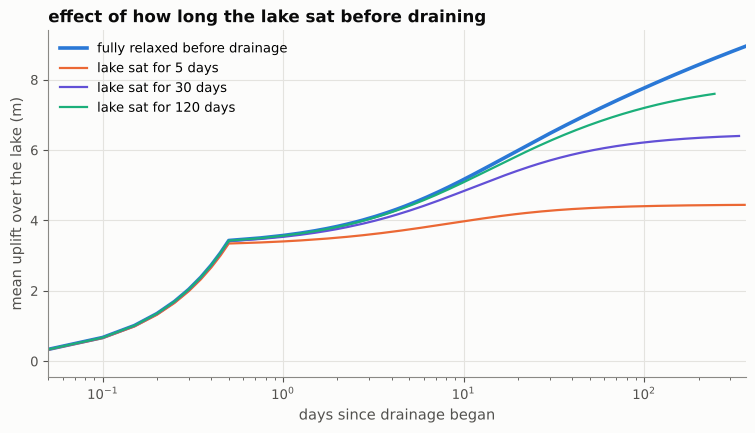

In [12]:
U = resp.uplift_lake_mean.values
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(td, U, color=ps.VISCO, lw=2.6, label="fully relaxed before drainage")
for Th, c in zip([5, 30, 120], [ps.ELASTIC, ps.ACCENT, ps.ISO]):
    m = td <= td[-1] - Th
    UTh = U[m] - (np.interp(td[m] + Th, td, U) - np.interp(Th, td, U))
    ax.plot(td[m], UTh, color=c, lw=1.6, label=f"lake sat for {Th} days")
    print(f"sat {Th:>3} days: change after 100 days {np.interp(100, td[m], UTh):5.2f} m "
          f"(fully relaxed: {np.interp(100, td, U):5.2f} m)")
ax.set(xscale="log", xlim=(0.05, 365), xlabel="days since drainage began", ylabel="mean uplift over the lake (m)",
       title="effect of how long the lake sat before draining")
ax.legend();

## 8. Record the response

Two Datasets are written to `outputs/` as compressed NetCDF, both cropped to the area around the lake:

* `resp`, on the plate grid. It holds every model field at the output times: the change in deflection `w` and the `uplift`, the change in load `q`, the moment potentials `mu`, and the surface stresses. It also holds the step-by-step time series and the isostatic limit. Its `attrs` carry the shelf parameters.
* `surface`, on the routing grid. It holds the DEM, the lake, the uplift interpolated onto the DEM, and the new surface `dem + uplift`.

In [13]:
def save(ds, name):
    enc = {v: {"zlib": True, "complevel": 4, **({"dtype": "float32"} if ds[v].dtype.kind == "f" else {})}
           for v in ds.data_vars}
    path = os.path.join(OUT_DIR, name)
    ds.to_netcdf(path, encoding=enc)
    print(f"{path}: {os.path.getsize(path) / 1e6:.1f} MB")

meta = dict(lake_label=int(LAKE), lake_volume_m3=float(info.volume), lake_max_depth_m=float(info.max_depth),
            melt_m=MELT, dem_file=DEM_FILE, routing="fill-spill-merge (fillspillmerge wrapper)")
resp.attrs.update(meta)

uplift = xr.concat([plate.to_grid(resp.uplift.isel(time=i), "uplift") for i in range(resp.sizes["time"])], dim="time")
surface = xr.Dataset(
    {"dem": dem, "lake_depth": lake_depth, "floating": floating.astype("int8"),
     "uplift": uplift.assign_attrs(units="m", long_name="uplift since drainage began")},
    attrs={**resp.attrs},
).assign_coords(time=resp.time, time_days=resp.time_days)
surface["surface_after"] = (surface.dem + surface.uplift).transpose("time", "y", "x").assign_attrs(units="m", long_name="surface after drainage")

save(resp.sel(**BOX), f"lake_{LAKE}_drainage_plate.nc")
save(surface.sel(**BOX), f"lake_{LAKE}_drainage_surface.nc")
xr.open_dataset(os.path.join(OUT_DIR, f"lake_{LAKE}_drainage_surface.nc"))

outputs/lake_6319_drainage_plate.nc: 2.5 MB
outputs/lake_6319_drainage_surface.nc: 2.9 MB


<xarray.Dataset> Size: 6MB
Dimensions:        (y: 288, x: 354, time: 6)
Coordinates:
  * y              (y) float64 2kB 1.957e+06 1.957e+06 ... 1.938e+06 1.938e+06
  * x              (x) float64 3kB 8e+05 8.001e+05 ... 8.225e+05 8.226e+05
  * time           (time) float64 48B 4.32e+04 1.728e+05 ... 8.64e+06 3.154e+07
    time_days      (time) float64 48B ...
    spatial_ref    int64 8B ...
Data variables:
    dem            (y, x) float32 408kB ...
    lake_depth     (y, x) float32 408kB ...
    floating       (y, x) int8 102kB ...
    uplift         (time, y, x) float32 2MB ...
    surface_after  (time, y, x) float32 2MB ...
Attributes: (12/25)
    E:                 1000000000.0
    nu:                0.3
    nu_v:              0.5
    eta:               100000000000000.0
    rho_i:             917.0
    rho_sw:            1028.0
    ...                ...
    plate_dx:          128.0
    lake_label:        6319
    lake_max_depth_m:  31.26390103220882
    melt_m:            0.5
    dem_file:          ../python/notebooks/rema_subsets/dem_small_2.tif
    routing:           fill-spill-merge (fillspillmerge wrapper)

## 9. A second lake, fully afloat in mid-shelf

Choosing a lake by location: this is the largest lake that is entirely afloat, on the northern part of the shelf. It is smaller and narrower than the grounding-line lake.

lake 526: 7.4 Mm³ over 4.9 km², max depth 7.4 m, 100% afloat


drained in 22 s of computing
day   0.5: lake 526 at  21% of isostatic, lake 6319 at  30%
day    10: lake 526 at  30% of isostatic, lake 6319 at  45%
day   100: lake 526 at  43% of isostatic, lake 6319 at  68%
day   365: lake 526 at  54% of isostatic, lake 6319 at  78%


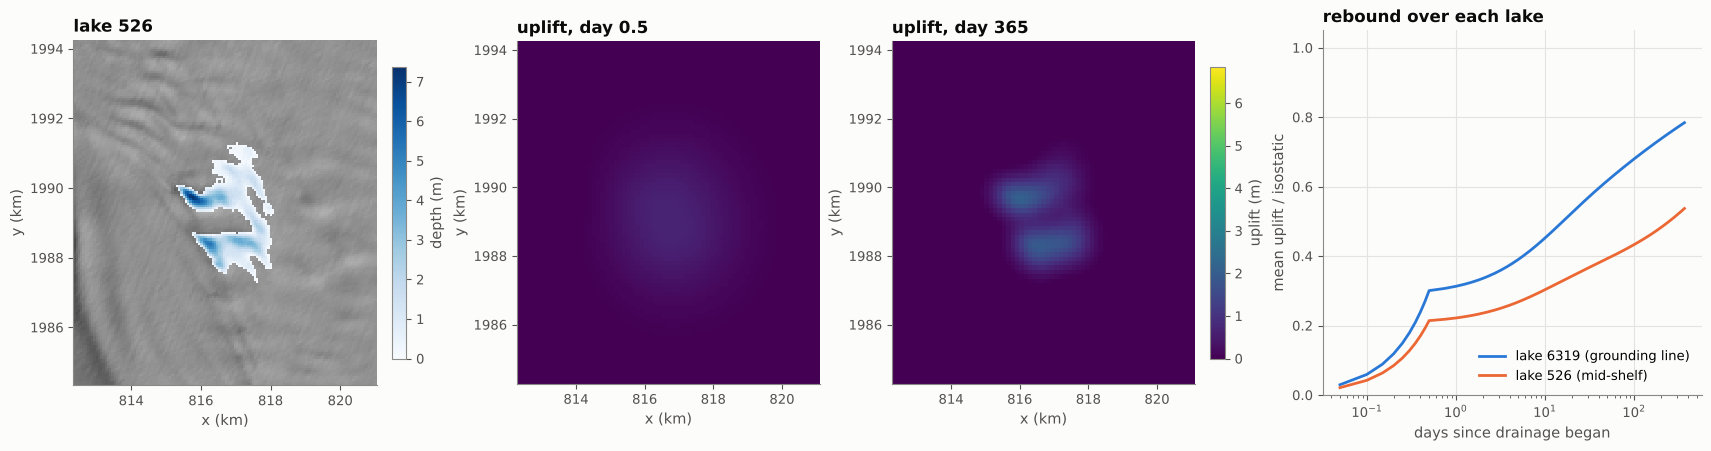

In [14]:
LAKE2 = pick_lake(lakes, near=(816.7e3, 1989.1e3))
info2 = lakes.sel(lake=LAKE2)
lake2 = water.where(labels == LAKE2, 0.0)
print(f"lake {LAKE2}: {float(info2.volume) / 1e6:.1f} Mm³ over {float(info2.area) / 1e6:.1f} km², "
      f"max depth {float(info2.max_depth):.1f} m, {100 * float(info2.floating_fraction):.0f}% afloat")
t0 = time.perf_counter()
resp2 = drain_lake(plate, lake2, OUT, drain_time=DRAIN)
print(f"drained in {time.perf_counter() - t0:.0f} s of computing")

BOX2 = box_around(lake2, margin=3e3)
fig = plt.figure(figsize=(17, 4.4), constrained_layout=True)
gs = fig.add_gridspec(1, 4, width_ratios=[1, 1, 1, 1.25])
ax = [fig.add_subplot(gs[i]) for i in range(4)]
show_map(ax[0], hs.sel(**BOX2), f"lake {LAKE2}", cmap="gray", vmin=0, vmax=1)
im = show_map(ax[0], lake2.sel(**BOX2).where(lake2.sel(**BOX2) > 0), cmap="Blues", vmin=0)
plt.colorbar(im, ax=ax[0], shrink=0.8, label="depth (m)")
vm = float(resp2.uplift_isostatic.sel(**BOX2).max())
for a, t_ in zip(ax[1:3], [0.5, 365]):
    im = show_map(a, resp2.uplift.sel(time_days=t_, method="nearest").sel(**BOX2), f"uplift, day {t_:g}",
                  cmap="viridis", vmin=0, vmax=vm)
plt.colorbar(im, ax=ax[2], shrink=0.8, label="uplift (m)")
for r, name, c in [(resp, f"lake {LAKE} (grounding line)", ps.VISCO), (resp2, f"lake {LAKE2} (mid-shelf)", ps.ELASTIC)]:
    ax[3].semilogx(r.step_time_days[1:], r.rebound_fraction[1:], color=c, label=name)
ax[3].set(xlabel="days since drainage began", ylabel="mean uplift / isostatic", ylim=(0, 1.05),
          title="rebound over each lake")
ax[3].legend(loc="lower right");
for t_ in (0.5, 10, 100, 365):
    print(f"day {t_:>5g}: lake {LAKE2} at {100 * float(resp2.rebound_fraction.sel(step_time_days=t_, method='nearest')):3.0f}% "
          f"of isostatic, lake {LAKE} at {100 * float(resp.rebound_fraction.sel(step_time_days=t_, method='nearest')):3.0f}%")

## 10. Checks

The two checks below rerun the grounding-line lake:

* **(a) time step:** with every plate step halved, out to day 30.
* **(b) plate grid:** on plate grids of 256 m and 64 m as well as 128 m, to the end of drainage. The 64 m plate has 300,000 unknowns, and its sparse factorisation takes about half a minute.

Both compare against the run above.

In [15]:
t0 = time.perf_counter()
fine = drain_lake(plate, lake_depth, [30 * DAY], drain_time=DRAIN, dt_drain=DRAIN / 20,
                  dt_early=0.125 * DAY, dt_late=0.5 * DAY)
ref30 = resp.uplift.sel(time_days=30, method="nearest")
err_t = float(abs(fine.uplift.isel(time=-1) - ref30).max() / ref30.max())
print(f"(a) halving every time step changes the day-30 uplift by at most {err_t:.1e} of its peak")

print("(b) at the end of drainage (day 0.5):")
for c_ in (4, 2, 1):
    if c_ == 2:
        r_ = resp
    else:
        r_ = drain_lake(ShelfPlate(dem, floating, shelf, coarsen=c_), lake_depth, [DRAIN], drain_time=DRAIN)
    print(f"    {64 * c_:>3} m plate: rebound fraction {float(r_.rebound_fraction.sel(step_time_days=0.5)):.3f}, "
          f"largest uplift {float(r_.uplift_max.sel(step_time_days=0.5)):.2f} m")
print(f"checks: {time.perf_counter() - t0:.0f} s")

(a) halving every time step changes the day-30 uplift by at most 1.5e-05 of its peak
(b) at the end of drainage (day 0.5):


    256 m plate: rebound fraction 0.345, largest uplift 8.48 m
    128 m plate: rebound fraction 0.301, largest uplift 7.92 m


     64 m plate: rebound fraction 0.284, largest uplift 7.77 m
checks: 85 s


## Summary

* **Routing.** 0.5 m of melt on this REMA subset fills about 8,300 lakes. The largest, 344 Mm³ and up to 31 m deep, is ponded against the grounding line. About two-thirds of the melt leaves the domain.
* **Rebound of the grounding-line lake.** Draining it (from a fully relaxed state) lifts the ice by up to about 8 m within the 12 hours of drainage. That is only ~30% of the isostatic rebound, because much of the deepest water sits within a flexural length of the grounding line, where the ice is pinned. Creep takes the rebound to ~45% after 10 days, ~70% after 100 days and ~80% after a year. Near the grounding line it is slower still.
* **Stress.** Upward bending puts the surface over the old lake into tension of about 1.2 MPa just after drainage, falling to ~0.7 MPa after 10 days and ~0.3 MPa after 100 days. These are large enough to matter for fracture. The hinge along the grounding line goes into compression.
* **Mid-shelf lake.** A smaller lake made of narrow (~1 km) lobes rebounds less and more slowly: ~20% during drainage and ~55% after a year. Features narrower than $2\pi\ell \approx 5.5$ km are held back by the plate's stiffness and relax on times of order $\tau[1 + (2\pi\ell/\lambda)^4]$.
* **The relaxed assumption.** It holds only for lakes that sat for months. If a lake drains days after filling, the shelf is still sagging under it, and that unfinished sag cancels much of the rebound: 100 days after drainage the mean uplift is 4.4 m for a lake that sat 5 days, against 7.8 m if fully relaxed. Section 7 gets this from the same run, with no extra computation.
* **Numerics.** The time step is far from limiting. The plate grid matters near the grounding line, where the stair-stepped mask acts as a clamped edge that is only first-order accurate. For this lake the rebound fraction at the end of drainage is 0.35, 0.30 and 0.28 on 256, 128 and 64 m plates; the largest uplift converges faster (8.5, 7.9, 7.8 m).
* **Outputs.** The full response (deflection, load, moment potentials, stresses, time series and parameters) is in `outputs/lake_<label>_drainage_plate.nc`. The surface before and after drainage, on the DEM grid, is in `outputs/lake_<label>_drainage_surface.nc`.

**Caveats:** uniform thickness (here 400 m) and uniform rheology; grounded ice fixed at the 500 m mask; the REMA surface over existing lakes is a water or ice surface, not the lake bed; no fracture.